# Optimizations and Gradient Decent

## Introduction to Optimizations

**Problem:** Given a smooth function $f:\mathbb{R}^d \to \mathbb{R},$ find the smallest value of the function $f$ and also a point $x_0$ such that
$$
f(x_0) = \min{x\in\mathbb{R}^d}f(x).
$$
We have two small problems:

- Find the smallest value of the function:
$$
\min{x\in D}f(x),
$$
where $D$ is a subset of $\mathbb{R}^d$.

- Find the point $x_0$, which is called the minimizer, such that $f(x_0)$ is the smallest value.
$$
\text{argmin} f(x), x\in D.
$$

**Example:** Given the function $f:\mathbb{R}^2\to \mathbb{R}$, where
$$
f(x, y) = x^2 + |\sin(x) - y|^2 - 1,
$$
then

$$
\min f(x, y) = -1
$$

and

$$
\text{argmin} f(x, y) = (0, 0).
$$

In this case $(x_0, y_0) = (0, 0)$ is a minimizer.

**Example:** Let $M$ be a model that contains $10$ parameters $\beta_1, \ldots, \beta_{10}$ and $L(\beta_1, \ldots, \beta_{10})$ be the loss (error) function. When er train the model, we just find the minimizer of $(\beta_1, \ldots, \beta_{10})$ that gives the smallest error for the model.

### Convex function

The function $f$ is conves if
$$
f(\lambda x + (1-\lambda)y) \le \lambda f(x) + (1-\lambda)f(y)
$$
for any $\lambda \in [0,1]$ and for any $x$ and $y$.

**Theorem:** If $f$ is convex and differential, then there exist a unique minimizer such that
$$
f(x_*) = \min f(x), \quad \nabla f(x_*) = 0.
$$

## Exploratory Analysis for Minimizers

- Use `matplotlib` to understand the nature of minimizers.
- Check if the function has the minimizer or not.

**Example:** Consider the functions $f(x, y) = x^2 + 3y^2$ and $g(x, y) = x^2 - 3y^2$.

Use the exploratory analysis to understand the minimizer of these functions.

### Surface plot of the functions

In [1]:
from asyncio import format_call_graph

import numpy as np
import matplotlib.pyplot as plt
from IPython.core.compilerop import PyCF_MASK
from prompt_toolkit.key_binding.bindings.mouse import xterm_sgr_mouse_events

In [2]:
# plot the surface for f and g
xs = np.linspace(-5, 5, 200)
ys = np.linspace(-5, 5, 200)

In [3]:
# create the meshgrid
x_vals, y_vals = np.meshgrid(xs, ys)

In [4]:
print(x_vals.shape)

(200, 200)


In [5]:
# define the functions
def f(x, y):
    return x**2 + 3*y**2

def g(x, y):
    return x**2 - 3*y**2

In [6]:
# compute the value of functions
f_vals = f(x_vals, y_vals)
g_vals = g(x_vals, y_vals)

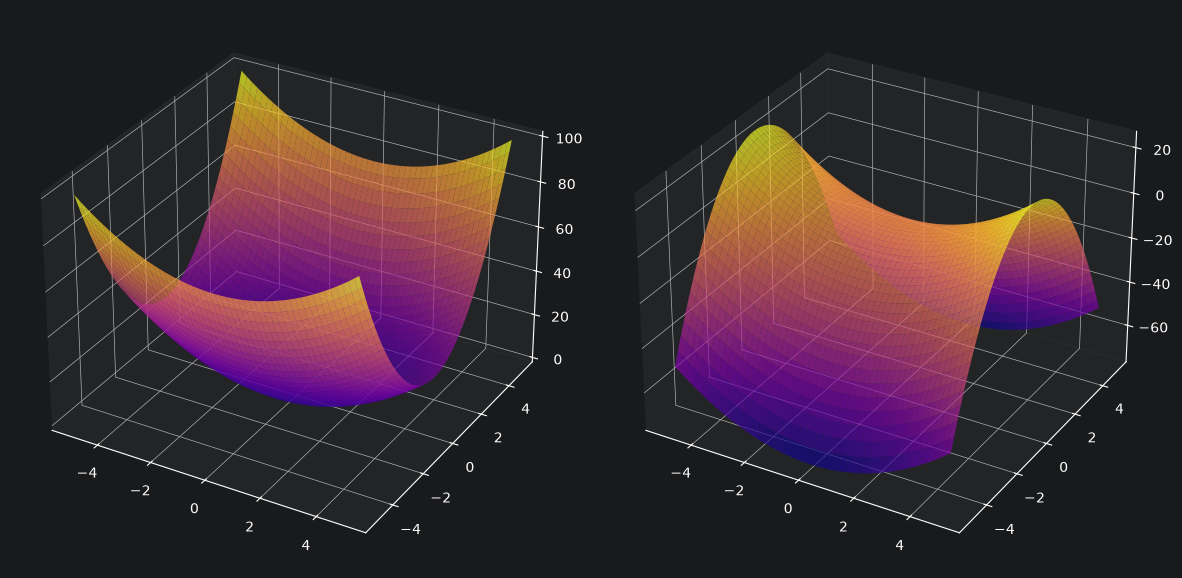

In [19]:
# use these values to plot the surface
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(12, 6), subplot_kw={'projection': '3d'})

# activate the 3d on the first axis
# ax_1 = plt.subplot(1, 2, 1, projection='3d')
# finetune the surface plot
# ax_1.plot_surface(x_vals, y_vals, f_vals, label="function f(x,y)")
axs[0].plot_surface(x_vals, y_vals, f_vals, label="function f(x,y)", alpha=0.7, cmap="plasma")

# alpha gives the transparency
# cmap gives the color palette
# ax_2 = plt.subplot(1, 2, 2, projection='3d')
axs[1].plot_surface(x_vals, y_vals, g_vals, label="function g(x,y)", alpha=0.7, cmap="plasma")

plt.tight_layout()
plt.show()

## Critical Points and Contour Configurations

- Critical points: Are solutions to gradient function.
- Compute the gradient $\nabla f = [f_x, f_y]$.
- Solve $\nabla f = 0$ for $x, y$.

**Example:** Find critical points for two functions $f$ and $g$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [5]:
# need some function from sympy
from sympy import symbols, solve, diff

In [7]:
# define x and y vars
x, y = symbols("x y")

In [8]:
f = x**2 + 3*y**2
f

x**2 + 3*y**2

In [10]:
g = x**2 - 3*y**2

In [11]:
# compute the gradient
f_x = diff(f, x)
f_y = diff(f, y)
grad_f = [f_x, f_y]

In [12]:
# critical points for f
solve(grad_f, x, y)

{x: 0, y: 0}

Function $f(x, y)$ has only one critical point $(0, 0)$.

In [13]:
# compute gradient for g
g_x = diff(g, x)
g_y = diff(g, y)
grad_g = [g_x, g_y]

In [14]:
# critical points for g
solve(grad_g, x, y)

{x: 0, y: 0}

## Contour Configurations for the minimizers

**Contour Curves:** Let $f(x, y)$ be a function and $c\in\mathbb{R}$. Define
$$
\Gamma_c = \{ (x, y)\ :\ f(x, y) = c \}
$$,
then $\Gamma_c$ is called the contour curve at the level $c$.

We have two configurations for the critical points:

- If the critical point is the local max/min, then contour curves concentric rings.
- If the critical point is the saddle point, the contour curves are intersecting.

**Example:** Plot the contour configurations for $f$ and $g$

In [15]:
# create xs and ys on each axis
xs = np.linspace(-5, 5, 200)
ys = np.linspace(-5, 5, 200)

In [16]:
# create the domain (meshgrid) for x and y
x_vals, y_vals = np.meshgrid(xs, ys)

In [17]:
# plugin into the functiions
f_vals = x_vals**2+3*y_vals**2
g_vals = x_vals**2-3*y_vals**2

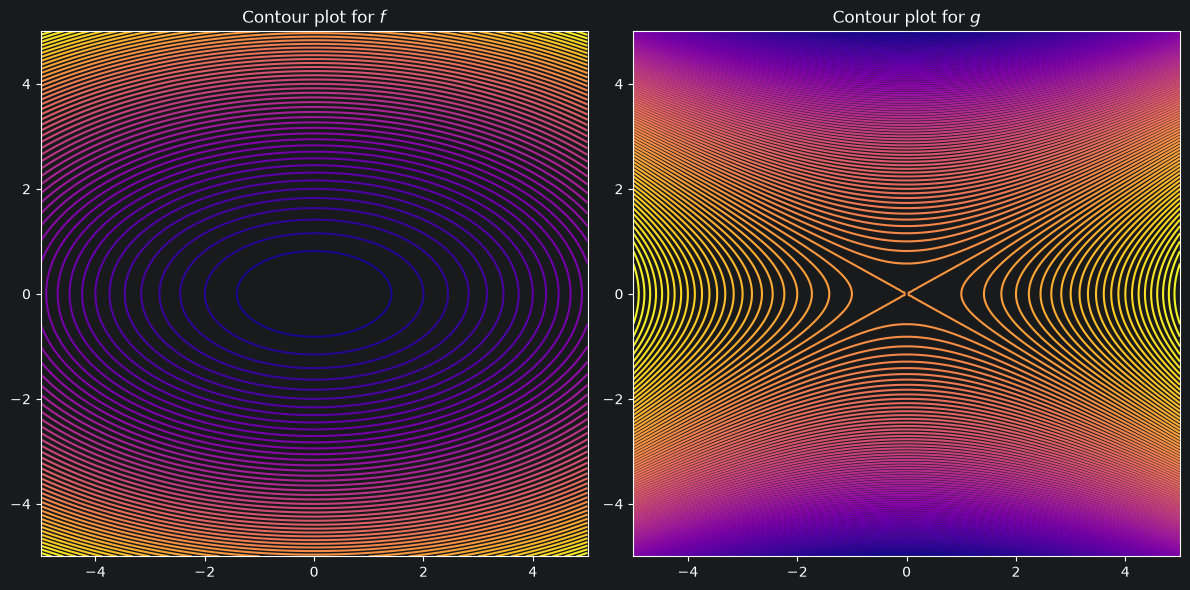

In [26]:
# plot the contour for both f and g (side by side)
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(12, 6))

# plot the first contour
axs[0].contour(x_vals, y_vals, f_vals, levels=50, cmap="plasma")
axs[0].set_title(r"Contour plot for $f$")

# plot the contour for g
axs[1].contour(x_vals, y_vals, g_vals, levels=100, cmap="plasma")
axs[1].set_title(r"Contour plot for $g$")

plt.tight_layout()
plt.show()

In case we have concentric rings, we know it is either the local max or local min. So we have to label the values on the rings to have a clearer conclusion.

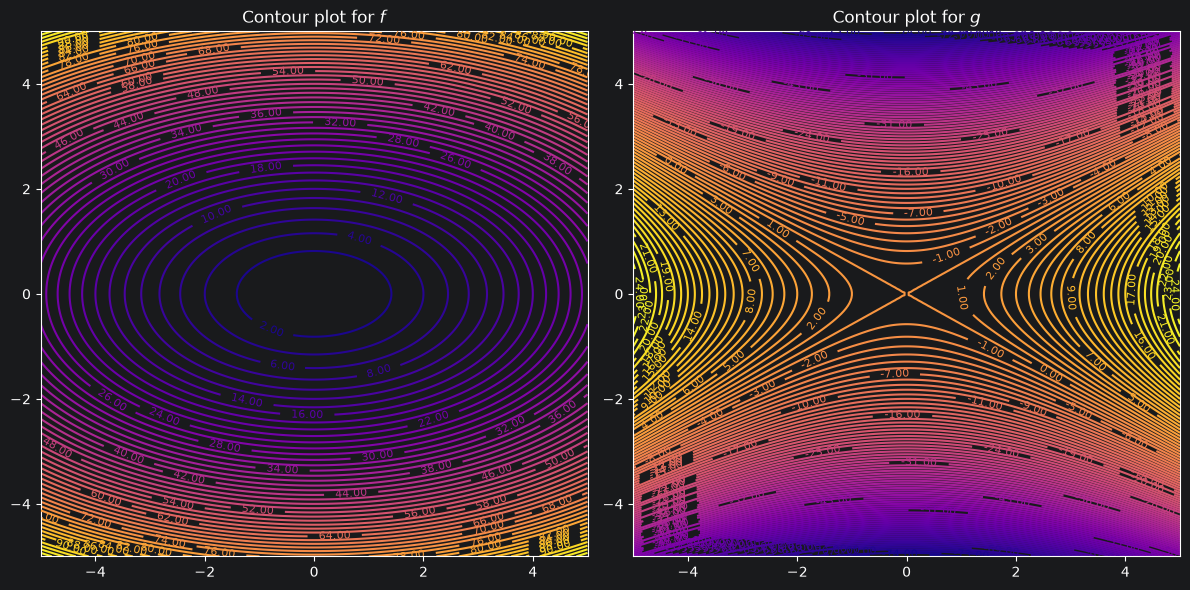

In [28]:
# How to label on the contour curves.
# plot the contour for both f and g (side by side)
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(12, 6))

# define the contour set
cs_f = axs[0].contour(x_vals, y_vals, f_vals, levels=50, cmap="plasma")
axs[0].set_title(r"Contour plot for $f$")
# label the values on the contour set
axs[0].clabel(cs_f, fontsize=8, fmt="%0.2f")

# define the contour set for g
cs_g = axs[1].contour(x_vals, y_vals, g_vals, levels=100, cmap="plasma")
axs[1].set_title(r"Contour plot for $g$")
# label values on the contour set
axs[1].clabel(cs_g, fontsize=8, fmt="%0.2f")

plt.tight_layout()
plt.show()

**Example:** USe the exploratory analysis to identify the local max, local min, or saddle points of the function
$$
f(x, y) = 3x^2y + y^3 - 3x^2 - 3y^2 + 2
$$

In [29]:
x, y = symbols("x y")

In [31]:
f = 3*x**2*y + y**3 - 3*x**2 - 3*y**2 + 2
f

3*x**2*y - 3*x**2 + y**3 - 3*y**2 + 2

In [32]:
grad_f = [diff(f, x), diff(f, y)]

In [33]:
# find critical points
solve(grad_f, x, y)

[(-1, 1), (0, 0), (0, 2), (1, 1)]

We have 4 critical points and we can pick the range for $x$ and $y$

In [65]:
xs = np.linspace(-2, 2, 200)
ys = np.linspace(-1, 3, 200)

In [66]:
# meshgrid
x_vals, y_vals = np.meshgrid(xs, ys)

In [67]:
# evaluate f
f_vals = 3*x_vals**2*y_vals + y_vals**3 - 3*x_vals**2 - 3*y_vals**2 + 2

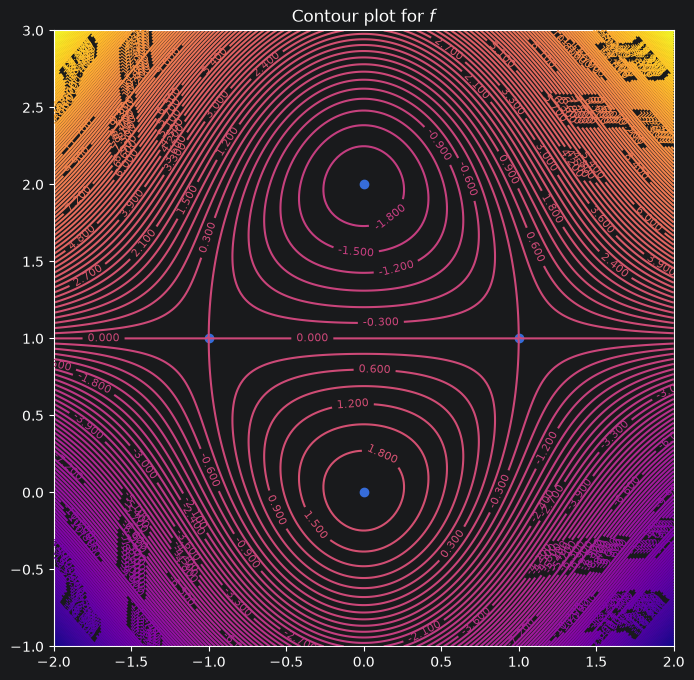

In [68]:
# plot the contour
fig, ax = plt.subplots(figsize=(8, 8))

# define the contour set
cs = ax.contour(x_vals, y_vals, f_vals, levels=200, cmap="plasma")
ax.set_title(r"Contour plot for $f$")
# label the values on the contour set
ax.clabel(cs, fontsize=8, fmt="%0.3f")

# plot 4 points to indicate the critical points
# (-1, 1), (0, 0), (0, 2), (1, 1)
ax.scatter([[-1, 0, 0, 1]], [1, 0, 2, 1], marker="o")

plt.show()

**Conclusion:** Based on the contour plot, the function has two saddle points $(-1, 1)$ and $(1,1)$. The local max is at $(0,0)$ and the local min is at $(0,2)$.

## Gradient Descent Algorithm

**Problem:** Consider the optimization problem

$$
\text{argmax} f(x, y), \quad (x, y)\in D
$$

Suppose the problem has a solution ${x_*, y_*}$ such that
$$
f(x_*, y_*) = \min_{(x, y)\in D} f(x, y)
$$

Then we need an algorithm to find $(x_*, y_*)$.

**Gradient Descent Algorithm**

- Initiate the first point $(x_0, y_0)$ (cab be any tuple in the domain)
- Compute the gradient of $f$ at $(x_0, y_0)$, say
$$
v_0 = \nabla f(x_0, y_0)
$$
- Update the next point (move to the opposite direction of the gradient):
$$
(x_1, y_1) = (x_0, y_0) - \alpha * \nabla f(x_0, y_0),
$$
where $\alpha$ is a small number between $0$ and $1$ acting as the learning rate.
- Redo the calculation for the gradient at $(x_1, y_1)$ and repeat the process.
- The process will stop when we reach the max iterations or the norm of gradient is nearly zero.

**Example:** Use the gradient descent to find the minimizer of the function.
$$
f(x, y) = (x-2)^2 + 0.8*(y-3)^2 + 0.25xy
$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# define the function
def f(x, y, a=0.8, b=0.25):
    return (x-2)**2 + a*(y-3)**2 + b*x*y

For the gradient, we have
$$
f_x = 2(x-2) + \frac{1}{4}y, \quad f_y = 2\frac{8}{10}(y-3) + \frac{1}{4}x
$$

In [3]:
# define the gradient
def grad(x, y, a=0.8, b=0.25):
    # return a vector
    return np.array([
        2*(x-2) + b*y, 2*a*(y-3)+b*x
    ])

In [4]:
# test the gradient at some points
(x, y) = (0, 0)
v = grad(x, y)
print(v)

[-4.  -4.8]


In [8]:
def gradient_descent(grad, init_pt, max_iter=1000, alpha=0.1, tol=1e-8):
    # return a list of convergent points to the minimizer
    # return the latest norm of the gradient
    x0, y0 = init_pt
    convergent_pts = [init_pt] # always capture the init_pt in the convergent pts
    for i in range(max_iter):
        # compute the gradient
        v = grad(x0, y0)
        # roll to the lower point
        (x_next, y_next) = np.array([x0, y0]) - alpha * v
        # append this point to the convergent points
        convergent_pts.append((x_next, y_next))
        # reset x0, y0
        x0 = x_next
        y0 = y_next
        # stop condition
        last_norm = np.linalg.norm(v)
        if last_norm < tol:
            break

    # return outside of the for loop
    return convergent_pts, last_norm

In [13]:
# test with the given function f(x,y)
init_point = (1.5, 3.7)
alpha = 0.5
max_iter = 60
tol = 1e-6

In [14]:
convergent_pts, last_norm = gradient_descent(grad, init_point, max_iter, alpha, tol)

In [17]:
print(lsat_norm)

5.081607821024473e-07


In [18]:
# the minimizer is the last point of the convergent points
x_min, y_min = convergent_pts[-1]

In [19]:
print(x_min, y_min)

1.6573704792411839 2.7410359370670543


In [23]:
# test as different init pt
# test with the given function f(x, y)
init_point = (20, 10)
alpha = 0.5
max_iter = 60
tol = 1e-6

In [24]:
convergent_pts, last_norm = gradient_descent(grad, init_point, max_iter=max_iter, alpha=alpha, tol=tol)

In [25]:
print(last_norm)

7.647259182454569e-07


In [26]:
x_min, y_min = convergent_pts[-1]
print(x_min, y_min)

1.657370576148149 2.7410357354401143


Plot the convergent points and the contours to see the convergent path of the algorithm.

In [27]:
xs = np.linspace(-10, 20, 200)
ys = np.linspace(-5, 10, 200)

In [28]:
# create the meshgrid
x_vals, y_vals = np.meshgrid(xs, ys)

In [29]:
f_vals = f(x_vals, y_vals)

In [36]:
# extract x values and y values from convergent pts
x_pts = []
y_pts = []
for (u,v) in convergent_pts:
    x_pts.append(u)
    y_pts.append(v)

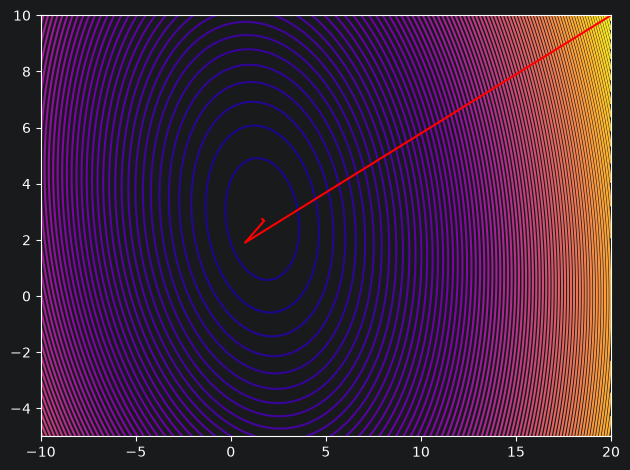

In [37]:
fig, ax = plt.subplots()

# plot the contour
ax.contour(x_vals, y_vals, f_vals, levels=100, cmap="plasma")

# plot the convergent path of convergent points
ax.plot(x_pts, y_pts, color="red")

plt.tight_layout()
plt.show()

In [53]:
# test with a lower learning rate
init_point = (20, 10)
alpha = 0.01
max_iter = 100
tol = 1e-6

In [51]:
convergent_pts, last_norm = gradient_descent(grad, init_point, max_iter, alpha, tol)

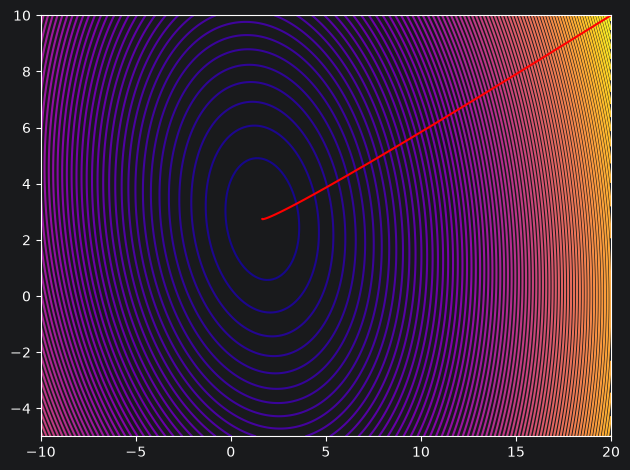

In [52]:
fig, ax = plt.subplots()

# plot the contour
ax.contour(x_vals, y_vals, f_vals, levels=100, cmap="plasma")

# extract x and y values
x_pts = []
y_pts = []

for (u,v) in convergent_pts:
    x_pts.append(u)
    y_pts.append(v)

# plot the convergent path of convergent points
ax.plot(x_pts, y_pts, color="red")

plt.tight_layout()
plt.show()